# Lysosome Xenium (0617, 4-well arsenite plate): QC, well assignment, and gRNA perturbation check

Uses `lyso_final_clusters.h5ad` (58,347 cells x 480 genes, Xenium in situ panel + pre-computed
Leiden clustering / cell-type annotation / UMAP).

Steps:
1. QC results
2. UMAP colored by `cell_type`
3. Assign each cell to one of the 4 imaging wells (top_left/top_right/bottom_left/bottom_right)
   using the same affine-registration keypoints described in `run_4well_pipeline.py`, and drop
   cells that fall outside all four wells
4. UMAP colored by well assignment
5. Identify the 122 gRNA-barcode probes in the panel (named `<TARGET>-<N>`) and call a per-cell
   gRNA assignment
6. Number of cells assigned to each gRNA
7. For the target genes that also have their own plain expression probe in this panel, test
   whether cells carrying that gene's gRNA show reduced expression of the target gene
   (knockdown check)


In [1]:
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

sc.settings.verbosity = 1
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"


In [2]:
adata = sc.read_h5ad("lyso_final_clusters.h5ad")
adata

AnnData object with n_obs × n_vars = 58347 × 480
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'leiden', 'cell_type'
    var: 'gene_ids', 'feature_types', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'cell_type_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## 1. QC results

In [3]:
qc_cols = ["total_counts", "n_genes_by_counts", "cell_area", "nucleus_area",
           "nucleus_count", "pct_counts_in_top_50_genes"]
adata.obs[qc_cols].describe()

,total_counts,n_genes_by_counts,cell_area,nucleus_area,nucleus_count,pct_counts_in_top_50_genes
count,58347.000000,58347.000000,58347.000000,58329.000000,58347.000000,58347.000000
mean,684.576233,114.961283,105.398441,65.322334,1.009563,84.499219
std,156.214828,11.514585,33.587128,12.955173,0.102137,2.528621
min,500.000000,80.000000,44.162814,6.457344,0.000000,65.792474
25%,575.000000,107.000000,84.306722,56.987190,1.000000,82.848392
50%,647.000000,114.000000,95.686097,62.992971,1.000000,84.591195
75%,748.000000,122.000000,115.961254,71.121096,1.000000,86.248412
max,2120.000000,206.000000,561.247052,265.292978,3.000000,94.395797


/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/

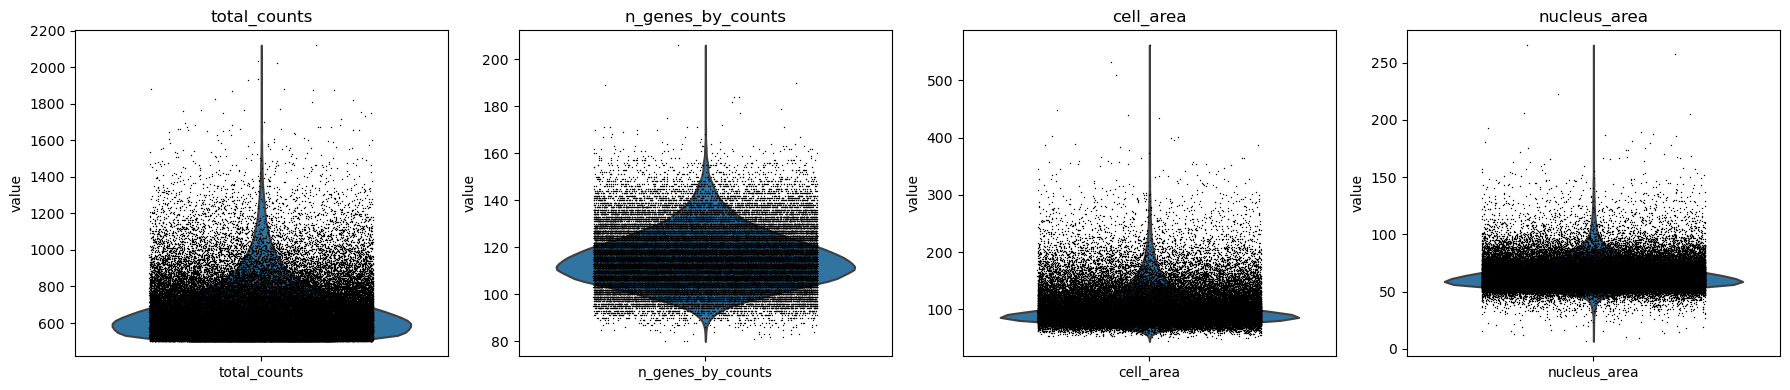

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["total_counts", "n_genes_by_counts", "cell_area", "nucleus_area"]):
    sc.pl.violin(adata, col, jitter=0.3, ax=ax, show=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

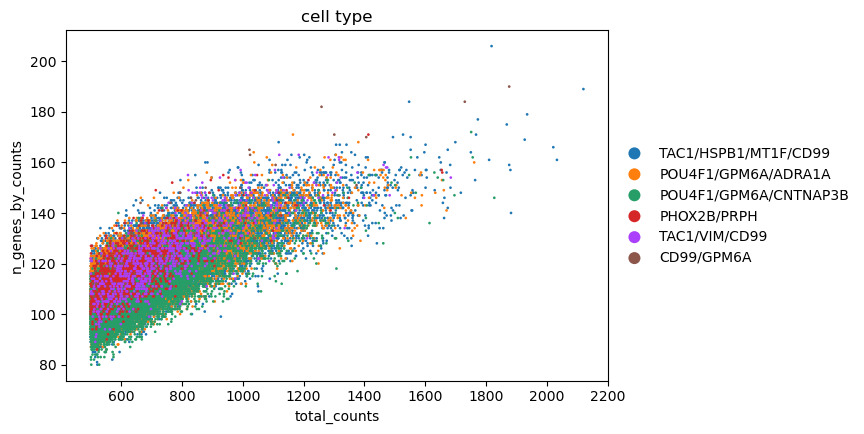

In [5]:
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="cell_type", size=15)

/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


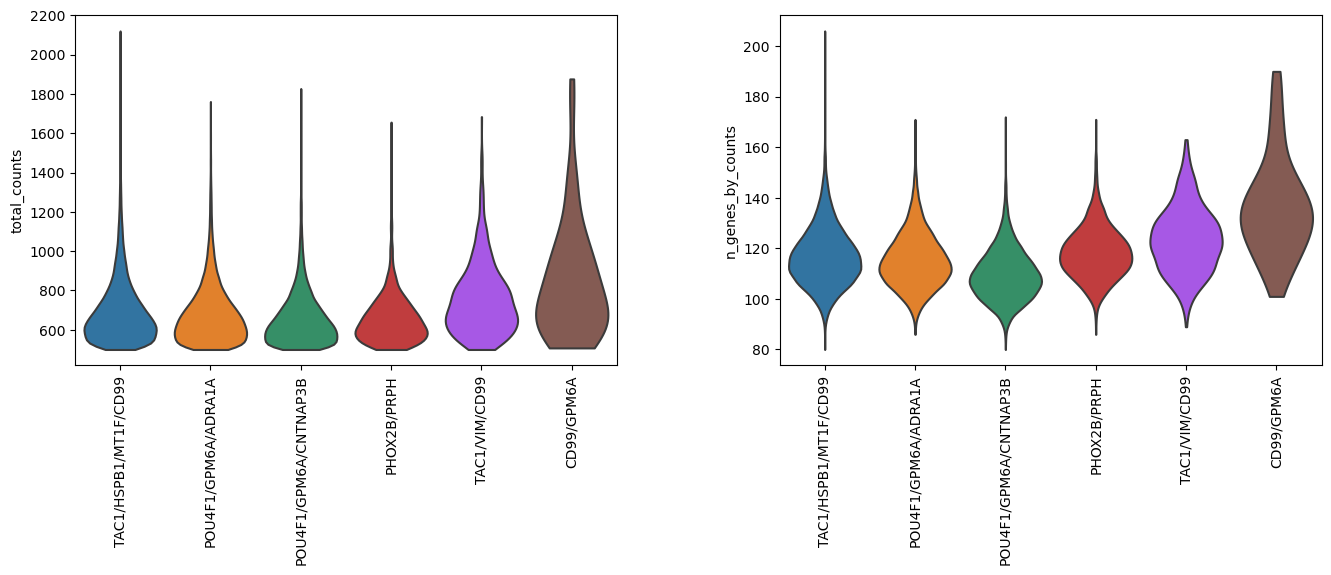

In [6]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts"], groupby="cell_type",
             rotation=90, stripplot=False)

## 2. UMAP colored by cell type

/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


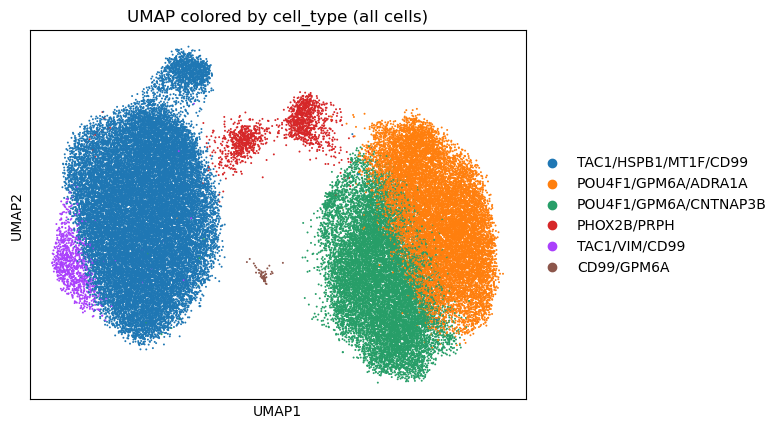

In [7]:
sc.pl.umap(adata, color="cell_type", size=8, legend_loc="right margin",
           title="UMAP colored by cell_type (all cells)")

## 3. Assign cells to one of the 4 imaging wells

The BFP/lysosome timelapse imaging was done on a 4-well plate (arsenite-treated: top_left,
top_right; untreated: bottom_left, bottom_right), and each well was registered to the (single,
continuous) Xenium capture area **independently**, producing its own affine matrix
(`<well>/matrix.csv`, fit from `<well>/keypoints.csv`) -- see `run_4well_pipeline.py`.

`keypoints.csv`'s `fixedX`/`fixedY` columns are the Xenium-side keypoints, already in **Xenium
pixel space**. We use the bounding box of each well's keypoints as that well's footprint in
Xenium pixel space, convert each cell's `x_centroid`/`y_centroid` (given in microns) to Xenium
pixels with the same `PIXEL_SIZE_XENIUM = 0.2125 um/px` used in `run_4well_pipeline.py`, and
assign a cell to whichever well's box contains it. Cells outside all four boxes (the gaps
between wells and the plate edges, which were not covered by the BFP imaging grid) are dropped.


In [8]:
PIXEL_SIZE_XENIUM = 0.2125  # um/px, matches run_4well_pipeline.py

WELL_DIRS = {
    "top_left": "lyso_top_left",
    "top_right": "top_right_alignment_files",
    "bottom_left": "bottom_left",
    "bottom_right": "bottom_right_alignment_files",
}

well_boxes = {}
for well, d in WELL_DIRS.items():
    kp = pd.read_csv(f"{d}/keypoints.csv")
    well_boxes[well] = (kp["fixedX"].min(), kp["fixedX"].max(),
                         kp["fixedY"].min(), kp["fixedY"].max())
    print(f"{well:>13s}  x=[{well_boxes[well][0]:9.1f}, {well_boxes[well][1]:9.1f}]  "
          f"y=[{well_boxes[well][2]:9.1f}, {well_boxes[well][3]:9.1f}]  (n_keypoints={len(kp)})")

     top_left  x=[   2296.4,   17720.7]  y=[   6982.0,   43267.9]  (n_keypoints=81)
    top_right  x=[  30630.8,   44877.5]  y=[   3624.4,   42527.8]  (n_keypoints=102)
  bottom_left  x=[   1937.2,   17833.3]  y=[  59388.6,  100984.4]  (n_keypoints=130)
 bottom_right  x=[  29919.9,   43964.9]  y=[  59433.6,  100419.0]  (n_keypoints=132)


In [9]:
x_px = adata.obs["x_centroid"].to_numpy() / PIXEL_SIZE_XENIUM
y_px = adata.obs["y_centroid"].to_numpy() / PIXEL_SIZE_XENIUM

well_assignment = pd.Series(pd.NA, index=adata.obs_names, dtype=object)
for well, (x0, x1, y0, y1) in well_boxes.items():
    mask = (x_px >= x0) & (x_px <= x1) & (y_px >= y0) & (y_px <= y1)
    overlap = well_assignment.notna() & mask
    assert overlap.sum() == 0, f"{well} box overlaps a previously assigned well for {overlap.sum()} cells"
    well_assignment[mask] = well

adata.obs["well"] = well_assignment
adata.obs["well"].value_counts(dropna=False)

well
top_left        15945
bottom_left     15115
bottom_right    11777
top_right        9592
<NA>             5918
Name: count, dtype: int64

In [10]:
n_before = adata.n_obs
adata_wells = adata[adata.obs["well"].notna()].copy()
adata_wells.obs["well"] = adata_wells.obs["well"].astype("category")
print(f"Kept {adata_wells.n_obs} / {n_before} cells inside one of the four wells "
      f"({n_before - adata_wells.n_obs} cells outside all four well footprints were dropped).")
print()
print(adata_wells.obs["well"].value_counts())

Kept 52429 / 58347 cells inside one of the four wells (5918 cells outside all four well footprints were dropped).

well
top_left        15945
bottom_left     15115
bottom_right    11777
top_right        9592
Name: count, dtype: int64


## 4. UMAP colored by well assignment

/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/mingjiay/miniconda3/envs/scanpy0923/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


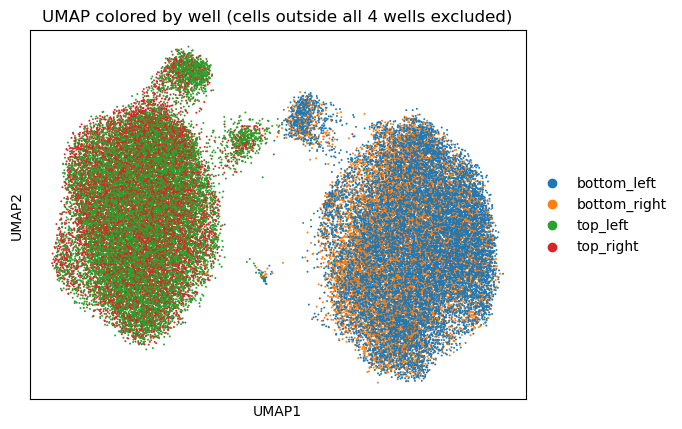

In [11]:
sc.pl.umap(adata_wells, color="well", size=8, legend_loc="right margin",
           title="UMAP colored by well (cells outside all 4 wells excluded)")

## 5. Identify gRNA probes and call a per-cell gRNA assignment

The 480-gene panel includes 122 CRISPR gRNA-barcode probes named `<TARGET>-<N>` (a stricter
regex requiring a trailing `-<digit>` is used so real hyphenated gene names like `HLA-DMB` /
`HLA-DQA1` aren't mistaken for gRNA probes). There are 24 target genes plus a `Negative_control`
non-targeting set, each represented by ~5 distinct guides (`LHX9` and `PROX1` have 4).

From here on, everything is restricted to `adata_wells` (cells inside one of the 4 wells) since
the gRNA perturbation only applies to the CRISPR-treated wells.

**Assignment rule** (raw transcript counts, `layers["counts"]`, per cell):
- `Unassigned`: 0 total counts across all 122 gRNA probes
- `Ambiguous`: >0 total counts, but no single gRNA accounts for a majority (>50%) of them
- otherwise: assigned to the gRNA with the highest count (the "argmax" guide)

This mirrors the plurality-with-majority calling convention used elsewhere in this project for
noisy per-cell signals (e.g. the BFP-based perturbation calling in the CellProfiler morphology
notebooks), adapted here to raw in situ transcript counts instead of a continuous intensity.


In [12]:
grna_pattern = re.compile(r"^(.+)-(\d+)$")
grna_cols = [g for g in adata_wells.var_names if grna_pattern.match(g)]
target_genes = sorted({grna_pattern.match(g).group(1) for g in grna_cols})
print(f"{len(grna_cols)} gRNA probe columns found (of {adata_wells.n_vars} total panel genes)")
print(f"{len(target_genes)} distinct targets (incl. Negative_control): {target_genes}")

122 gRNA probe columns found (of 480 total panel genes)
25 distinct targets (incl. Negative_control): ['AFF1', 'BCL6', 'BNC2', 'CARHSP1', 'CREB5', 'EBF1', 'EBF3', 'HMGB2', 'ID2', 'ID4', 'ISL1', 'JUNB', 'KLF3', 'LHX9', 'MEIS2', 'NFE2L2', 'NFIB', 'Negative_control', 'ONECUT1', 'ONECUT2', 'PROX1', 'RUNX1', 'SIX1', 'SOX5', 'ZBTB7C']


In [13]:
grna_idx = [adata_wells.var_names.get_loc(g) for g in grna_cols]
grna_counts = adata_wells.layers["counts"][:, grna_idx]
if hasattr(grna_counts, "toarray"):
    grna_counts = grna_counts.toarray()
grna_counts = pd.DataFrame(grna_counts, index=adata_wells.obs_names, columns=grna_cols)

total = grna_counts.sum(axis=1)
top_grna = grna_counts.idxmax(axis=1)
top_count = grna_counts.max(axis=1)
top_share = np.where(total > 0, top_count / total.replace(0, np.nan), 0.0)

assigned_grna = pd.Series("Unassigned", index=adata_wells.obs_names, dtype=object)
has_signal = total > 0
assigned_grna[has_signal] = "Ambiguous"
confident = has_signal & (top_share > 0.5)
assigned_grna[confident] = top_grna[confident]

adata_wells.obs["grna"] = assigned_grna
adata_wells.obs["grna_gene"] = adata_wells.obs["grna"].map(
    lambda g: grna_pattern.match(g).group(1) if grna_pattern.match(g) else g
)

n_unassigned = (adata_wells.obs["grna"] == "Unassigned").sum()
n_ambiguous = (adata_wells.obs["grna"] == "Ambiguous").sum()
n_confident = adata_wells.n_obs - n_unassigned - n_ambiguous
print(f"Unassigned (0 gRNA counts):      {n_unassigned:6d}")
print(f"Ambiguous (no majority guide):   {n_ambiguous:6d}")
print(f"Confidently assigned to 1 gRNA:  {n_confident:6d}")
print()
single_count_frac = (total[confident] == top_count[confident]).mean()
print(f"Of confidently-assigned cells, {(total[confident]==1).mean()*100:.1f}% had only a single "
      f"gRNA transcript detected (weakest possible evidence) -- treat low-count calls with caution.")

Unassigned (0 gRNA counts):       12283
Ambiguous (no majority guide):     6653
Confidently assigned to 1 gRNA:   33493

Of confidently-assigned cells, 31.1% had only a single gRNA transcript detected (weakest possible evidence) -- treat low-count calls with caution.


## 6. Number of cells per gRNA

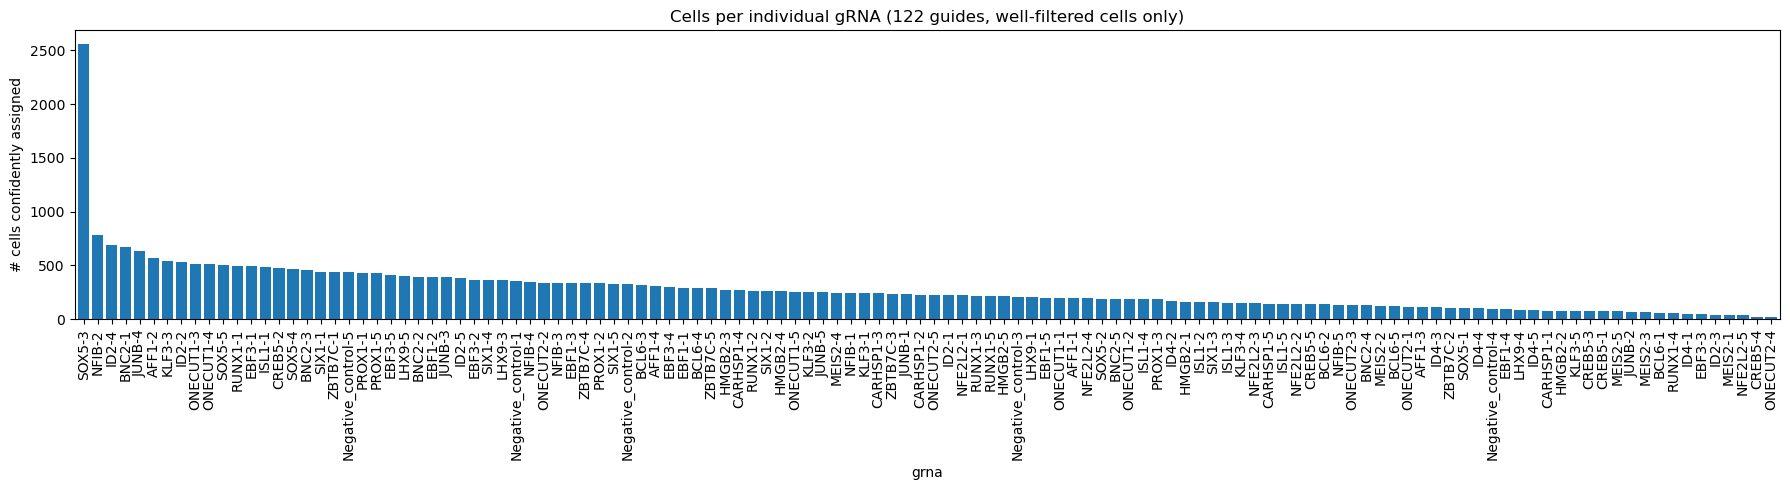

grna
SOX5-3       2558
NFIB-2        780
ID2-4         692
BNC2-1        668
JUNB-4        630
             ... 
ID2-3          43
MEIS2-1        42
NFE2L2-5       39
CREB5-4        19
ONECUT2-4      19
Name: count, Length: 122, dtype: int64

In [14]:
grna_cell_counts = (
    adata_wells.obs.loc[~adata_wells.obs["grna"].isin(["Unassigned", "Ambiguous"]), "grna"]
    .value_counts()
    .sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(18, 5))
grna_cell_counts.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("# cells confidently assigned")
ax.set_title("Cells per individual gRNA (122 guides, well-filtered cells only)")
plt.tight_layout()
plt.show()
grna_cell_counts

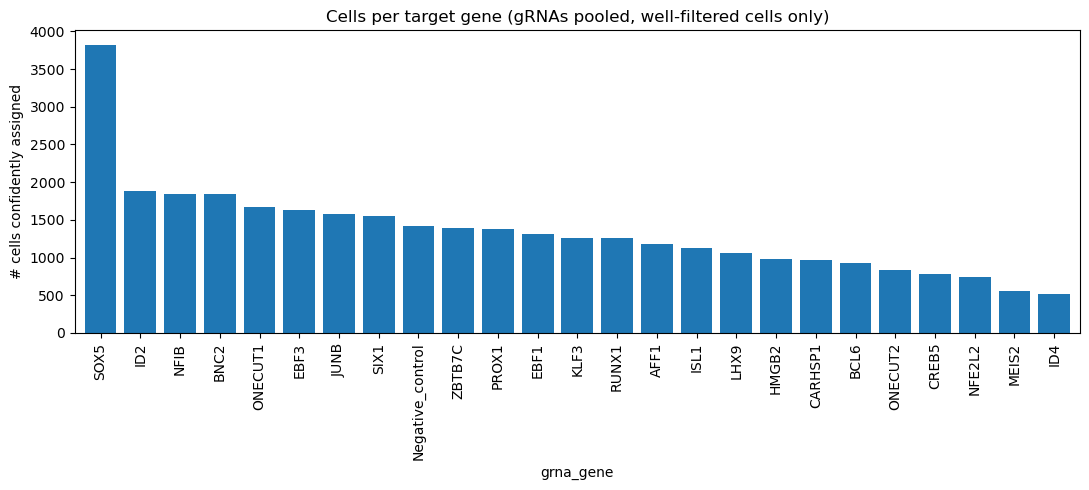

grna_gene
SOX5                3822
ID2                 1881
NFIB                1845
BNC2                1839
ONECUT1             1665
EBF3                1626
JUNB                1575
SIX1                1549
Negative_control    1424
ZBTB7C              1395
PROX1               1376
EBF1                1315
KLF3                1261
RUNX1               1255
AFF1                1181
ISL1                1121
LHX9                1061
HMGB2                986
CARHSP1              966
BCL6                 930
ONECUT2              830
CREB5                781
NFE2L2               744
MEIS2                550
ID4                  515
Name: count, dtype: int64

In [15]:
gene_cell_counts = (
    adata_wells.obs.loc[~adata_wells.obs["grna"].isin(["Unassigned", "Ambiguous"]), "grna_gene"]
    .value_counts()
    .sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(11, 5))
gene_cell_counts.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("# cells confidently assigned")
ax.set_title("Cells per target gene (gRNAs pooled, well-filtered cells only)")
plt.tight_layout()
plt.show()
gene_cell_counts

## 7. Does each gRNA reduce expression of its own target gene?

A direct "gRNA vs. its target's own transcript" knockdown check is only possible for target genes
that **also** have their own plain (non-gRNA-suffixed) expression probe elsewhere in this same
480-gene panel. That is true for only 5 of the 24 targeted genes:


In [16]:
has_plain_probe = {g: (g in adata_wells.var_names) for g in target_genes if g != "Negative_control"}
testable_genes = sorted([g for g, present in has_plain_probe.items() if present])
untestable_genes = sorted([g for g, present in has_plain_probe.items() if not present])
print("Testable (plain probe exists in panel):", testable_genes)
print()
print("NOT testable with this panel (no separate native-transcript probe, only the gRNA "
      "barcode itself):")
print(untestable_genes)

Testable (plain probe exists in panel): ['HMGB2', 'MEIS2', 'ONECUT2', 'PROX1', 'SIX1']

NOT testable with this panel (no separate native-transcript probe, only the gRNA barcode itself):
['AFF1', 'BCL6', 'BNC2', 'CARHSP1', 'CREB5', 'EBF1', 'EBF3', 'ID2', 'ID4', 'ISL1', 'JUNB', 'KLF3', 'LHX9', 'NFE2L2', 'NFIB', 'ONECUT1', 'RUNX1', 'SOX5', 'ZBTB7C']


In [17]:
control_mask = (adata_wells.obs["grna_gene"] == "Negative_control").to_numpy()

results = []
for gene in testable_genes:
    gene_idx = adata_wells.var_names.get_loc(gene)
    expr = adata_wells.X[:, gene_idx]
    expr = expr.toarray().flatten() if hasattr(expr, "toarray") else np.asarray(expr).flatten()

    ko_mask = (adata_wells.obs["grna_gene"] == gene).to_numpy()
    ko_expr, ctrl_expr = expr[ko_mask], expr[control_mask]

    stat, p = mannwhitneyu(ko_expr, ctrl_expr, alternative="two-sided")
    direction = "LOWER in gRNA cells (consistent with knockdown)" if ko_expr.mean() < ctrl_expr.mean() \
        else "higher in gRNA cells (opposite of expected knockdown)"
    results.append(dict(gene=gene, n_grna_cells=int(ko_mask.sum()), n_control_cells=int(ctrl_expr.shape[0]),
                         mean_expr_grna=ko_expr.mean(), mean_expr_control=ctrl_expr.mean(),
                         log2fc_grna_vs_ctrl=np.log2((ko_expr.mean()+1e-9)/(ctrl_expr.mean()+1e-9)),
                         p_value=p, direction=direction))

results_df = pd.DataFrame(results)
results_df["p_adj_bh"] = multipletests(results_df["p_value"], method="fdr_bh")[1]
results_df["knockdown_supported"] = (results_df["p_adj_bh"] < 0.05) & \
    results_df["direction"].str.startswith("LOWER")
results_df.sort_values("p_adj_bh")

,gene,n_grna_cells,n_control_cells,mean_expr_grna,mean_expr_control,log2fc_grna_vs_ctrl,p_value,direction,p_adj_bh,knockdown_supported
3,PROX1,1376,1424,0.434821,1.178709,-1.438713,1.493695e-139,LOWER in gRNA cells (consistent with knockdown),7.468475e-139,True
4,SIX1,1549,1424,0.053810,0.112037,-1.058028,1.528179e-08,LOWER in gRNA cells (consistent with knockdown),3.820447e-08,True
1,MEIS2,550,1424,0.090018,0.143021,-0.667940,1.057621e-03,LOWER in gRNA cells (consistent with knockdown),1.762702e-03,True
0,HMGB2,986,1424,1.038069,1.093183,-0.074633,9.248785e-02,LOWER in gRNA cells (consistent with knockdown),1.156098e-01,False
2,ONECUT2,830,1424,1.319437,1.359366,-0.043011,2.482602e-01,LOWER in gRNA cells (consistent with knockdown),2.482602e-01,False


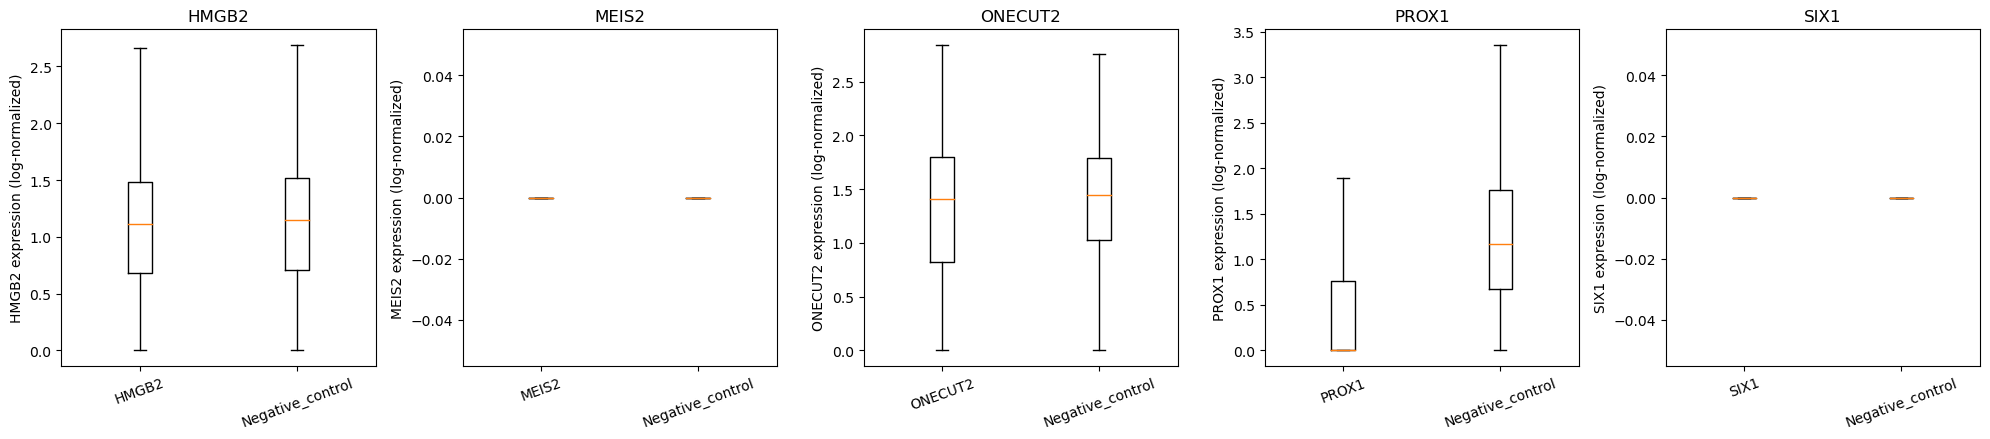

In [18]:
plot_df = adata_wells.obs[["grna_gene"]].copy()
for gene in testable_genes:
    gene_idx = adata_wells.var_names.get_loc(gene)
    expr = adata_wells.X[:, gene_idx]
    plot_df[gene] = expr.toarray().flatten() if hasattr(expr, "toarray") else np.asarray(expr).flatten()

fig, axes = plt.subplots(1, len(testable_genes), figsize=(4 * len(testable_genes), 4.5))
for ax, gene in zip(axes, testable_genes):
    sub = plot_df[plot_df["grna_gene"].isin([gene, "Negative_control"])]
    order = [gene, "Negative_control"]
    data = [sub.loc[sub["grna_gene"] == grp, gene].values for grp in order]
    ax.boxplot(data, labels=order, showfliers=False)
    ax.set_title(gene)
    ax.set_ylabel(f"{gene} expression (log-normalized)")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 8. gRNA counts per probe (count > 1 threshold)

Same per-guide cell-detection counts as above, but at the stricter `count > 1` threshold used for the downstream regression analyses, with the off-target cutoff (SOX5-3) marked.



In [ ]:
from IPython.display import Image
Image(filename="grna_counts_barplot_thresh1.png")